In [41]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.metrics import mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt


In [42]:
data = pd.read_csv("train.csv")
data['date'] = pd.to_datetime(data['date'])

# Single store-item
df = data[(data['store'] == 1) & (data['item'] == 1)].copy()
df = df.sort_values('date')

# Lag features
df['lag_1'] = df['sales'].shift(1)
df['lag_7'] = df['sales'].shift(7)
df['lag_14'] = df['sales'].shift(14)
df['lag_30'] = df['sales'].shift(30)
df['lag_365'] = df['sales'].shift(365)

# Rolling features (shifted to prevent leakage)
df['rolling_7'] = df['sales'].shift(1).rolling(7).mean()
df['rolling_14'] = df['sales'].shift(1).rolling(14).mean()
df['rolling_30'] = df['sales'].shift(1).rolling(30).mean()

# Calendar features
df['month'] = df['date'].dt.month
df['day_of_week'] = df['date'].dt.dayofweek

df = df.dropna()


In [43]:
split_index = int(len(df) * 0.8)

train = df.iloc[:split_index]
valid = df.iloc[split_index:]


In [44]:
features = [
    'lag_1','lag_7','lag_14','lag_30','lag_365',
    'rolling_7','rolling_14','rolling_30',
    'month','day_of_week'
]

X_train = train[features]
y_train = train['sales']

X_valid = valid[features]
y_valid = valid['sales']


In [45]:
model = xgb.XGBRegressor(
    n_estimators=500,
    learning_rate=0.01,
    max_depth=9,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)

model.fit(X_train, y_train)

predictions = model.predict(X_valid)


In [46]:
mae = mean_absolute_error(y_valid, predictions)
rmse = np.sqrt(mean_squared_error(y_valid, predictions))

print("Final XGBoost MAE:", mae)
print("Final XGBoost RMSE:", rmse)


Final XGBoost MAE: 4.161690711975098
Final XGBoost RMSE: 5.1756246291161485


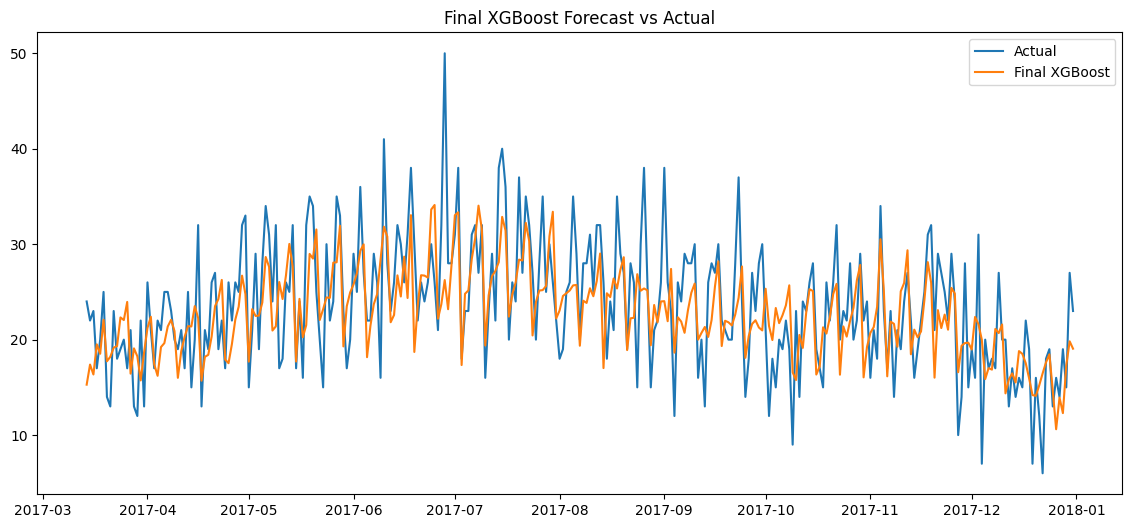

In [47]:
plt.figure(figsize=(14,6))
plt.plot(valid['date'], y_valid, label='Actual')
plt.plot(valid['date'], predictions, label='Final XGBoost')
plt.legend()
plt.title("Final XGBoost Forecast vs Actual")
plt.show()
